In [31]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
from scipy import signal

In [2]:
%pip install xrft 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


# Demonstrator 2 - Diffusive and dispersive advection schemes on eddies

## Aim of Tutorial

Here we choose to demonstrate how the diffusive and dispersive properties of the advection scheme impact the outcome of a simulation in the case of the formation of eddies.

To run this demonstrator you must have compiled the CANAL test case via the command :

``` ./makenemo -a CANAL```

## Running the simulation
This simulation will represent the eddies formed when noise on the velocity is added at the junction betweem two currents going at the same velocity in opposite directions along the x-axis.

To run this simulation, we need change set ```nn_initcase``` to ```2``` and ```ln_sshnoise``` to ```.true.``` in the ```namusr_def``` section of the namelist.

__To make the recquired changes you can either modify the files yourself by following or you can execute the cell below__

In [109]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_shear_cen2_all_grid.nc

chmod -R a+x /"$DIR"/demo2_cfg/

bash /"$DIR"/demo2_cfg/shear_cfg.sh "$DIR"

bash /"$DIR"/demo2_cfg/cen2_cfg.sh "$DIR"


+ set -v
set -u #Turn on error if usinf unset variables
+ set -u

if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'


sed -i.bak \
-e 's/rn_domszx.*=.*\!/rn_domszx      =      	2000.    !/' \
-e 's/rn_domszy.*=.*\!/rn_domszy      =       1000.   !/' \
-e 's/rn_domszz.*=.*\!/rn_domszz      =       1000.  !/' \
-e 's/rn_dx.*=.*\!/rn_dx      =       10.     !/' \
-e 's/rn_dy.*=.*\!/rn_dy      =       10.  !/' \
-e 's/rn_dz.*=.*\!/rn_dz      =       1000.  !/' \
-e 's/rn_0xratio.*=.*\!/rn_0xratio    =       0.5  !/' \
-e 's/rn_0yratio.*=.*\!/rn_0yratio    =       0.5  !

19,29c19,29
<    rn_domszx        =       1000.    !  x horizontal size         [km]
<    rn_domszy        =       1000.   !  y horizontal size         [km]
<    rn_domszz        =       1000.  !  z vertical size            [m]
<    rn_dx        =       20.     !  x horizontal resolution   [km]
<    rn_dy        =       20.  !  y horizontal resolution   [km]
<    rn_dz        =       1000.  !  z vertical resolution      [m]
<    rn_0xratio      =       0.5  !  x-domain ratio of the 0
<    rn_0yratio      =       0.5  !  y-domain ratio of the 0
<    nn_fcase  =       0  !  F computation (0:f0, 1:Beta, 2:real)
<    rn_ppgphi0      =       38.5  !  Reference latitude      [degrees]
<    rn_u10      =       0.  !  10m wind speed              [m/s]
---
>    rn_domszx      =      	2000.    !  x horizontal size         [km]
>    rn_domszy      =       1000.   !  y horizontal size         [km]
>    rn_domszz      =       1000.  !  z vertical size            [m]
>    rn_dx      =       10.     


real	0m51.489s
user	2m49.876s
sys	0m8.652s



Everything looks good



+ echo Run CANAL_shear_cen2_all_grid.nc completed


Run CANAL_shear_cen2_all_grid.nc completed


In [110]:
%%bash

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00


rm CANAL_shear_ubs_all_grid.nc
bash /"$DIR"/demo2_cfg/ubs_cfg.sh "$DIR"

+ set -v
set -u #Turn on error if using unset variables
+ set -u

if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'


sed -i.bak \
-e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .true.  !/' \
-e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .false. !/' \
-e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .false. !/' \
-e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/' \
-e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .false. !/' \
-e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/' \
-e 's/nn_ubs_v.*=.*\!

59c59
<    cn_exp =  'CANAL_shear_ubs'                                                                                    	                                    		 !  experience name
---
>    cn_exp =  'CANAL_saltblock_blp_traadvOFF'                                                                              	                                    		 !  experience name
167,168c167,168
<    ln_traadv_OFF        =       .false. !  No tracer advection
<    ln_traadv_cen        =       .false. !  2nd order centered scheme
---
>    ln_traadv_OFF	=	.false.	!  No tracer advection
>    ln_traadv_cen	=	.true.	!  2nd order centered scheme
171c171
<    ln_traadv_fct        =       .false. !  FCT scheme
---
>    ln_traadv_fct	=	.false.	!  FCT scheme
174c174
<    ln_traadv_mus        =       .false. !  MUSCL scheme
---
>    ln_traadv_mus	=	.false.	!  MUSCL scheme
176c176
<    ln_traadv_ubs        =       .true.  !  UBS scheme
---
>    ln_traadv_ubs	=	.false.	!  UBS scheme
178c178
<    ln_traadv_qck    


real	0m51.209s
user	2m56.376s
sys	0m9.882s



Everything looks good



+ echo Run CANAL_shear_ubs_all_grid.nc completed








Run CANAL_shear_ubs_all_grid.nc completed


In [111]:
%%bash

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

rm CANAL_shear_fct2_all_grid.nc
bash /"$DIR"/demo2_cfg/fct2_cfg.sh "$DIR"

+ set -v
set -u #Turn on error if using unset variables
+ set -u

if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'


sed -i.bak \
-e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .true.  !/' \
-e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .false. !/' \
-e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .false. !/' \
-e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/' \
-e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .false. !/' \
-e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/' \
-e 's/nn_fct_h.*=.*\!

59c59
<    cn_exp =  'CANAL_shear_fct2'                                                                                          	                                    		 !  experience name
---
>    cn_exp =  'CANAL_shear_ubs'                                                                                    	                                    		 !  experience name
171c171
<    ln_traadv_fct        =       .true.  !  FCT scheme
---
>    ln_traadv_fct        =       .false. !  FCT scheme
176c176
<    ln_traadv_ubs        =       .false. !  UBS scheme
---
>    ln_traadv_ubs        =       .true.  !  UBS scheme



sh /"$DIR"/run_nemo.sh && echo Run CANAL_shear_fct2_all_grid.nc completed
+ sh //Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/run_nemo.sh

real	0m54.042s
user	2m57.996s
sys	0m14.819s



Everything looks good



+ echo Run CANAL_shear_fct2_all_grid.nc completed








Run CANAL_shear_fct2_all_grid.nc completed


In [112]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''

## CEN2 (dispersive)

In [114]:
#Open the simulation using the xr library

cen2 = xr.open_dataset(rep+'CANAL_shear_cen2_all_grid.nc')
cen2

<xarray.Dataset> Size: 19MB
Dimensions:               (deptht: 2, axis_nbounds: 2, depthu: 2, depthv: 2,
                           time_counter: 20, y_grid_T: 101, x_grid_T: 201,
                           y_grid_F: 101, x_grid_F: 201, y_grid_U: 101,
                           x_grid_U: 201, y_grid_V: 101, x_grid_V: 201)
Coordinates: (12/13)
  * deptht                (deptht) float32 8B 500.0 1.5e+03
  * depthu                (depthu) float32 8B 500.0 1.5e+03
  * depthv                (depthv) float32 8B 500.0 1.5e+03
  * time_counter          (time_counter) object 160B 0001-01-01 12:00:00 ... ...
    time_centered         (time_counter) object 160B ...
    nav_lat_grid_T        (y_grid_T, x_grid_T) float32 81kB ...
    ...                    ...
    nav_lat_grid_F        (y_grid_F, x_grid_F) float32 81kB ...
    nav_lon_grid_F        (y_grid_F, x_grid_F) float32 81kB ...
    nav_lat_grid_U        (y_grid_U, x_grid_U) float32 81kB ...
    nav_lon_grid_U        (y_grid_U, x_grid_U) float32 81kB ...
    nav_lat_grid_V        (y_grid_V, x_grid_V) float32 81kB ...
    nav_lon_grid_V        (y_grid_V, x_grid_V) float32 81kB ...
Dimensions without coordinates: axis_nbounds, y_grid_T, x_grid_T, y_grid_F,
                                x_grid_F, y_grid_U, x_grid_U, y_grid_V, x_grid_V
Data variables: (12/13)
    deptht_bounds         (deptht, axis_nbounds) float32 16B ...
    depthu_bounds         (depthu, axis_nbounds) float32 16B ...
    depthv_bounds         (depthv, axis_nbounds) float32 16B ...
    time_centered_bounds  (time_counter, axis_nbounds) object 320B ...
    time_counter_bounds   (time_counter, axis_nbounds) object 320B ...
    soce                  (time_counter, deptht, y_grid_T, x_grid_T) float32 3MB ...
    ...                    ...
    sssgrad               (time_counter, y_grid_T, x_grid_T) float32 2MB ...
    ssrelvor              (time_counter, y_grid_F, x_grid_F) float32 2MB ...
    saltc                 (time_counter, y_grid_T, x_grid_T) float32 2MB ...
    salt2c                (time_counter, y_grid_T, x_grid_T) float32 2MB ...
    uoce                  (time_counter, depthu, y_grid_U, x_grid_U) float32 3MB ...
    voce                  (time_counter, depthv, y_grid_V, x_grid_V) float32 3MB ...
Attributes:
    name:         CANAL_saltblock_blp_traadvOFF_all_grid
    description:  ocean T/U/V grid variables
    title:        ocean T/U/V grid variables
    Conventions:  CF-1.6
    timeStamp:    2026-Oct-07 10:40:12 UTC
    uuid:         bae07693-7202-41bd-bfd9-48e0b36293a6

In [130]:
def show_t (t_list, param, title, file, rep=rep):
    " show_t displays a field from an xarray at given timesteps"
    "t_list : list of the timesteps displayed"
    "param : field displayed"
    "title : title of the figure"
    "file : name of the .nc array"
    "rep : path to the file (directory mentioned above by default)"
    im_list = []
    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(20, 5))
    for i, t in enumerate(t_list) : 
        # We select and show the desired field at different timesteps and at sea surface, excluding the walls
        data = dataset[param].isel(time_counter = t, deptht = 0)[1:-1, :]
        im = axes[i].imshow(data, origin='lower', interpolation = 'nearest', vmin=29, vmax=31)
        im_list.append(data)
        axes[i].set_title(f'{title} at (t={t+1} days)')
        axes[i].set_xlabel('x')
        axes[i].set_ylabel('y')
        fig.colorbar(im, ax=axes[i])
    plt.show()
    dataset.close()
    return im_list
    

In [131]:
t_list = [0, 10, 19]

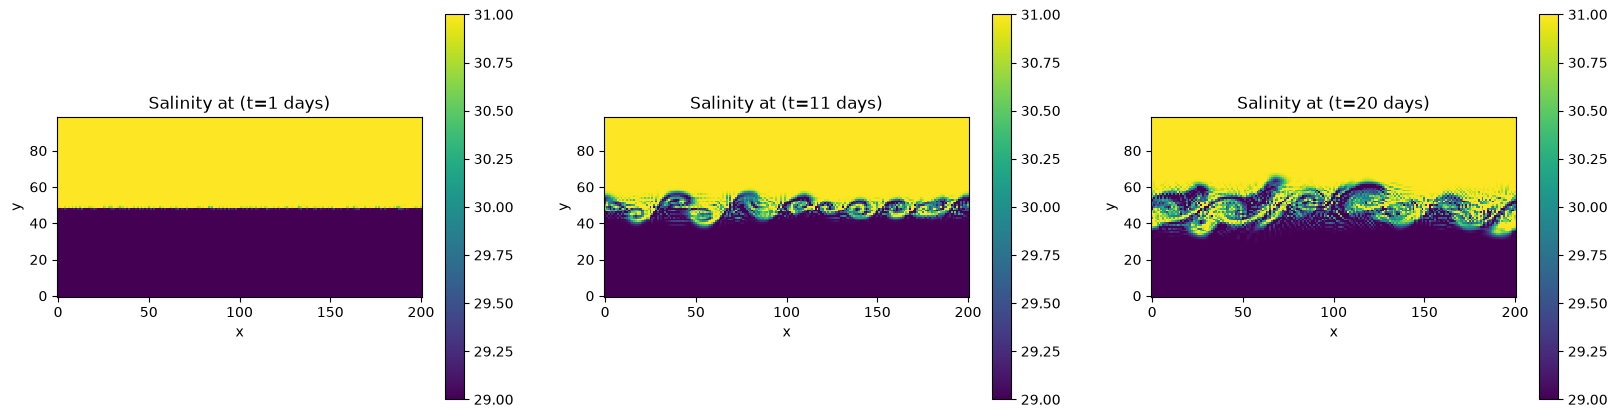

In [132]:
shear_cen2 = show_t(t_list, 'soce', 'Salinity', 'CANAL_shear_cen2_all_grid.nc', rep=rep)

The checkerboard pattern you should notice on the different figures are caused by the dispersive effect of CEN2. 

## UBS (diffusive)

In [133]:
#Open the simulation using the xr library

ubs = xr.open_dataset(rep+'CANAL_shear_ubs_all_grid.nc')
ubs

<xarray.Dataset> Size: 19MB
Dimensions:               (deptht: 2, axis_nbounds: 2, depthu: 2, depthv: 2,
                           time_counter: 20, y_grid_T: 101, x_grid_T: 201,
                           y_grid_F: 101, x_grid_F: 201, y_grid_U: 101,
                           x_grid_U: 201, y_grid_V: 101, x_grid_V: 201)
Coordinates: (12/13)
  * deptht                (deptht) float32 8B 500.0 1.5e+03
  * depthu                (depthu) float32 8B 500.0 1.5e+03
  * depthv                (depthv) float32 8B 500.0 1.5e+03
  * time_counter          (time_counter) object 160B 0001-01-01 12:00:00 ... ...
    time_centered         (time_counter) object 160B ...
    nav_lat_grid_T        (y_grid_T, x_grid_T) float32 81kB ...
    ...                    ...
    nav_lat_grid_F        (y_grid_F, x_grid_F) float32 81kB ...
    nav_lon_grid_F        (y_grid_F, x_grid_F) float32 81kB ...
    nav_lat_grid_U        (y_grid_U, x_grid_U) float32 81kB ...
    nav_lon_grid_U        (y_grid_U, x_grid_U) float32 81kB ...
    nav_lat_grid_V        (y_grid_V, x_grid_V) float32 81kB ...
    nav_lon_grid_V        (y_grid_V, x_grid_V) float32 81kB ...
Dimensions without coordinates: axis_nbounds, y_grid_T, x_grid_T, y_grid_F,
                                x_grid_F, y_grid_U, x_grid_U, y_grid_V, x_grid_V
Data variables: (12/13)
    deptht_bounds         (deptht, axis_nbounds) float32 16B ...
    depthu_bounds         (depthu, axis_nbounds) float32 16B ...
    depthv_bounds         (depthv, axis_nbounds) float32 16B ...
    time_centered_bounds  (time_counter, axis_nbounds) object 320B ...
    time_counter_bounds   (time_counter, axis_nbounds) object 320B ...
    soce                  (time_counter, deptht, y_grid_T, x_grid_T) float32 3MB ...
    ...                    ...
    sssgrad               (time_counter, y_grid_T, x_grid_T) float32 2MB ...
    ssrelvor              (time_counter, y_grid_F, x_grid_F) float32 2MB ...
    saltc                 (time_counter, y_grid_T, x_grid_T) float32 2MB ...
    salt2c                (time_counter, y_grid_T, x_grid_T) float32 2MB ...
    uoce                  (time_counter, depthu, y_grid_U, x_grid_U) float32 3MB ...
    voce                  (time_counter, depthv, y_grid_V, x_grid_V) float32 3MB ...
Attributes:
    name:         CANAL_shear_ubs_all_grid
    description:  ocean T/U/V grid variables
    title:        ocean T/U/V grid variables
    Conventions:  CF-1.6
    timeStamp:    2026-Oct-07 10:41:15 UTC
    uuid:         3ae390d3-429a-4006-b0da-f9791ba98c8b

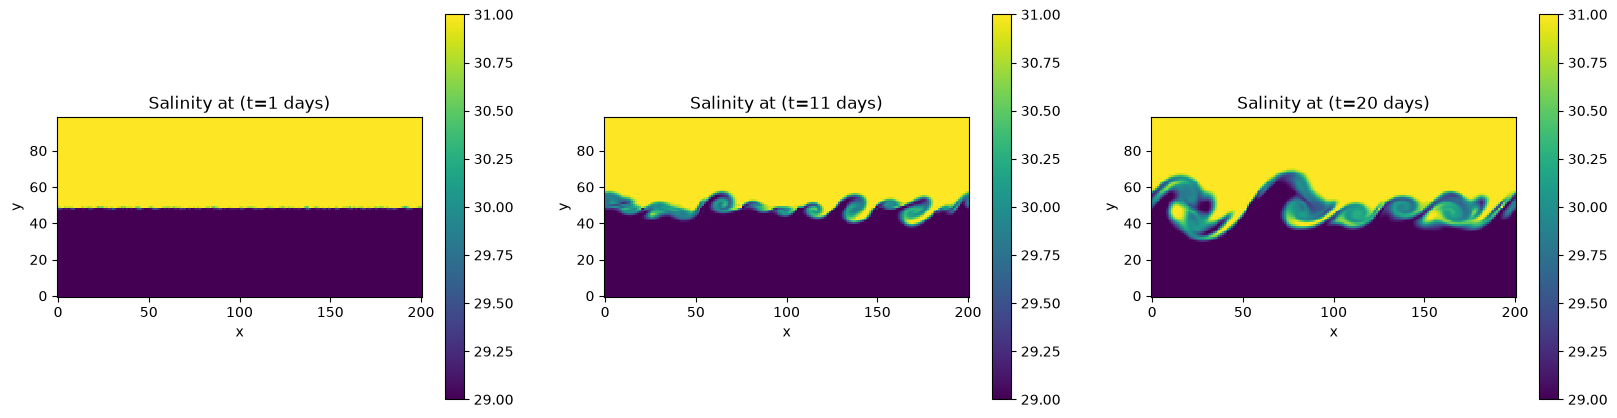

In [134]:
shear_ubs=show_t(t_list, 'soce', 'Salinity', 'CANAL_shear_ubs_all_grid.nc', rep=rep)

## FCT2 (corrected)

In [135]:
#Open the simulation using the xr library
fct2 = xr.open_dataset(rep+'CANAL_shear_fct2_all_grid.nc')
fct2

<xarray.Dataset> Size: 19MB
Dimensions:               (deptht: 2, axis_nbounds: 2, depthu: 2, depthv: 2,
                           time_counter: 20, y_grid_T: 101, x_grid_T: 201,
                           y_grid_F: 101, x_grid_F: 201, y_grid_U: 101,
                           x_grid_U: 201, y_grid_V: 101, x_grid_V: 201)
Coordinates: (12/13)
  * deptht                (deptht) float32 8B 500.0 1.5e+03
  * depthu                (depthu) float32 8B 500.0 1.5e+03
  * depthv                (depthv) float32 8B 500.0 1.5e+03
  * time_counter          (time_counter) object 160B 0001-01-01 12:00:00 ... ...
    time_centered         (time_counter) object 160B ...
    nav_lat_grid_T        (y_grid_T, x_grid_T) float32 81kB ...
    ...                    ...
    nav_lat_grid_F        (y_grid_F, x_grid_F) float32 81kB ...
    nav_lon_grid_F        (y_grid_F, x_grid_F) float32 81kB ...
    nav_lat_grid_U        (y_grid_U, x_grid_U) float32 81kB ...
    nav_lon_grid_U        (y_grid_U, x_grid_U) float32 81kB ...
    nav_lat_grid_V        (y_grid_V, x_grid_V) float32 81kB ...
    nav_lon_grid_V        (y_grid_V, x_grid_V) float32 81kB ...
Dimensions without coordinates: axis_nbounds, y_grid_T, x_grid_T, y_grid_F,
                                x_grid_F, y_grid_U, x_grid_U, y_grid_V, x_grid_V
Data variables: (12/13)
    deptht_bounds         (deptht, axis_nbounds) float32 16B ...
    depthu_bounds         (depthu, axis_nbounds) float32 16B ...
    depthv_bounds         (depthv, axis_nbounds) float32 16B ...
    time_centered_bounds  (time_counter, axis_nbounds) object 320B ...
    time_counter_bounds   (time_counter, axis_nbounds) object 320B ...
    soce                  (time_counter, deptht, y_grid_T, x_grid_T) float32 3MB ...
    ...                    ...
    sssgrad               (time_counter, y_grid_T, x_grid_T) float32 2MB ...
    ssrelvor              (time_counter, y_grid_F, x_grid_F) float32 2MB ...
    saltc                 (time_counter, y_grid_T, x_grid_T) float32 2MB ...
    salt2c                (time_counter, y_grid_T, x_grid_T) float32 2MB ...
    uoce                  (time_counter, depthu, y_grid_U, x_grid_U) float32 3MB ...
    voce                  (time_counter, depthv, y_grid_V, x_grid_V) float32 3MB ...
Attributes:
    name:         CANAL_shear_fct2_all_grid
    description:  ocean T/U/V grid variables
    title:        ocean T/U/V grid variables
    Conventions:  CF-1.6
    timeStamp:    2026-Oct-07 10:42:13 UTC
    uuid:         2f6cf11a-69e9-4580-bef4-96a363b06edf

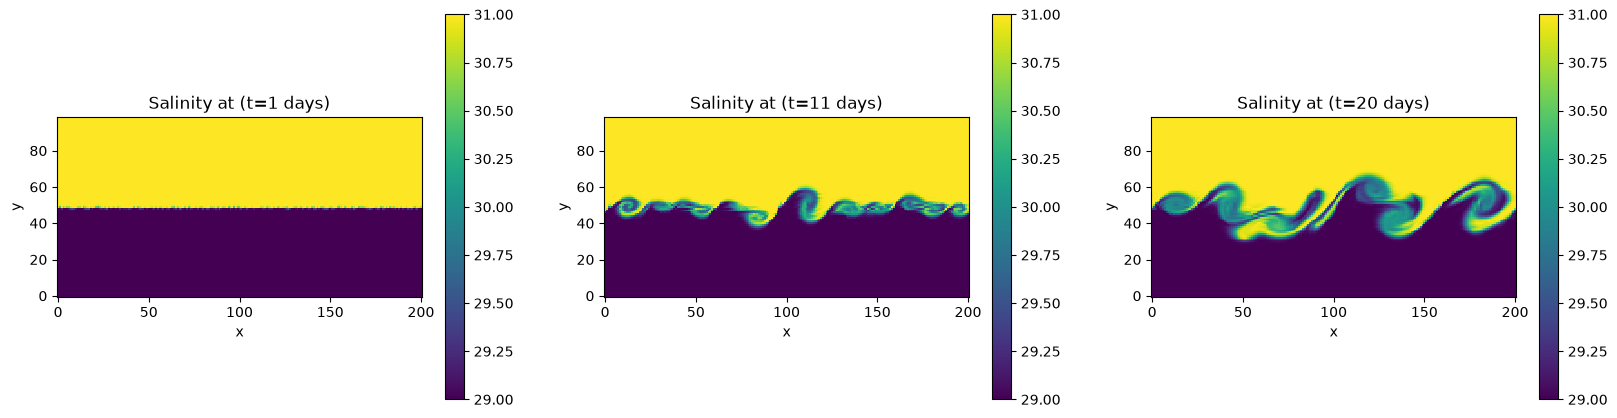

In [136]:
shear_fct2=show_t(t_list, 'soce', 'Salinity', 'CANAL_shear_fct2_all_grid.nc', rep=rep)

The diffusive property of the UBS and FCT schemes, softens the swirls of the eddies. The eddy appears less structured and less detailed at small scales. Rather than keeping the abrupt differences between high values and low values (front) at small scale to form small detailed structures (filaments of salinity), the mixing tends to a global mean value of salinity and the destruction of detailed patterns.

Text(0, 0.5, 'y')

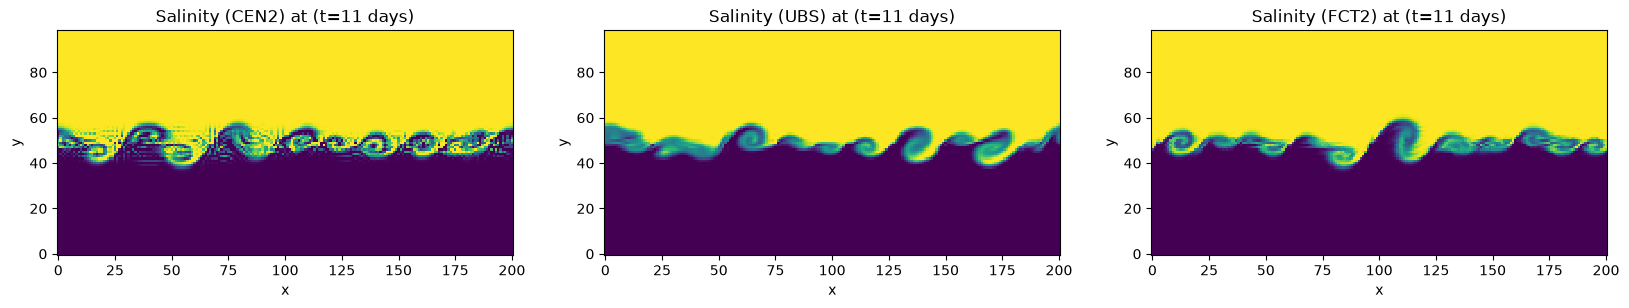

In [147]:
fig, axes = plt.subplots(1, 3, figsize=(20,5))

axes[0].imshow(shear_cen2[1], origin='lower', interpolation='nearest', vmin=29, vmax=31) 
axes[1].imshow(shear_ubs[1], origin='lower', interpolation='nearest',  vmin=29, vmax=31) 
axes[2].imshow(shear_fct2[1], origin='lower', interpolation='nearest', vmin=29, vmax=31) 

axes[0].set_title(f'Salinity (CEN2) at (t=11 days)')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[1].set_title(f'Salinity (UBS) at (t=11 days)')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
axes[2].set_title(f'Salinity (FCT2) at (t=11 days)')
axes[2].set_xlabel('x')
axes[2].set_ylabel('y')

## FCT2 Gradient

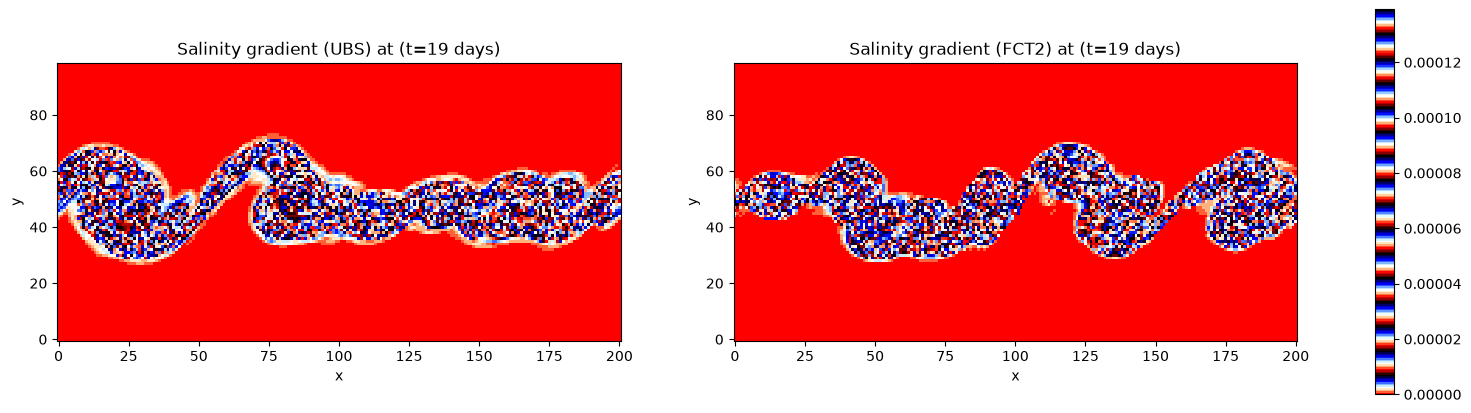

In [148]:

fig, axes = plt.subplots(1, 2, figsize=(20, 5))

# We select and show the desired field at different timesteps and at sea surface, excluding the walls
data = ubs['sssgrad'].isel(time_counter = 19)[1:-1, :]
im = axes[0].imshow(data, interpolation='nearest', origin='lower', cmap = 'flag')

axes[0].set_title(f'Salinity gradient (UBS) at (t=19 days)')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')

data = fct2['sssgrad'].isel(time_counter = 19)[1:-1, :]
im = axes[1].imshow(data, interpolation='nearest', origin='lower', cmap = 'flag')

axes[1].set_title(f'Salinity gradient (FCT2) at (t=19 days)')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')


fig.colorbar(im, ax=axes)
plt.show()

## Tracer variance

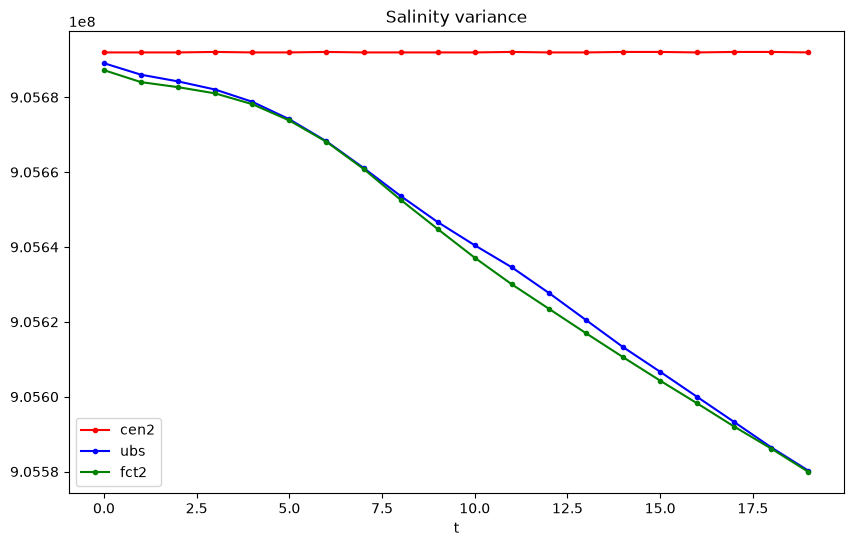

In [149]:
fig_salt2c, axes_salt2c = plt.subplots(1, 1, figsize=(10, 6))



s2c_cen2 = cen2['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
s2c_ubs = ubs['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
s2c_fct2 = fct2['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))


dep = np.arange(s2c_cen2.shape[0])

axes_salt2c.plot(dep,  s2c_cen2, 'r.-', label = 'cen2')
axes_salt2c.plot(dep,  s2c_ubs, 'b.-', label = 'ubs')
axes_salt2c.plot(dep,  s2c_fct2, 'g.-', label = 'fct2')

axes_salt2c.legend()
axes_salt2c.set_title("Salinity variance")
axes_salt2c.set_xlabel('t')

axes_salt2c.legend()


The decreasing curves of UBS and FCT is evidence that the schemes are diffusive. 

But the variance curve tells us only how much smoothing each scheme applies over time, not where in the field that smoothing is happening. A drop in variance could come from mild damping spread across the whole domain. To confirm our assumptio, that the strong damping is concentrated only at sharp fronts the graph of the variance alone is insufficient.

 To see this more directly, we look at the distribution of gradient magnitudes across the domain at a single timestep: a diffusive scheme should show fewer high-magnitude gradients (steep fronts get smoothed away), while a less diffusive scheme should retain more of them.

## Gradient magnitude distribution

Text(0, 0.5, 'Frequency')

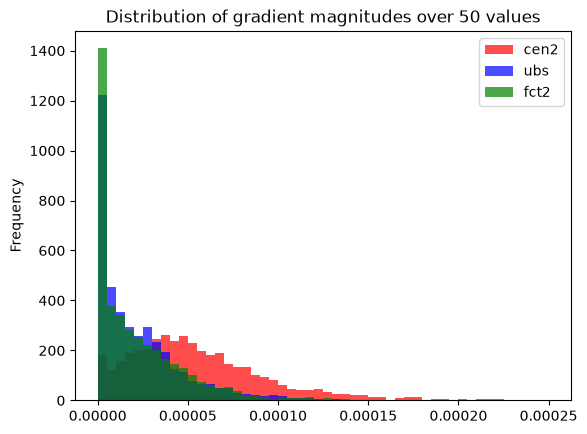

In [166]:
t = 15

cen2_grad = cen2.sssgrad.isel(time_counter = t)[40:60]
cen2_grad = np.array(cen2_grad)
cen2_grad_0 = cen2_grad[cen2_grad != 0]


ubs_grad = ubs.sssgrad.isel(time_counter = t)[40:60]
ubs_grad = np.array(ubs_grad)
ubs_grad_0 = ubs_grad[ubs_grad != 0]


fct2_grad = fct2.sssgrad.isel(time_counter = t)[40:60]
fct2_grad = np.array(fct2_grad)
fct2_grad_0 = fct2_grad[fct2_grad != 0]

plt.hist(cen2_grad_0, bins=50, range=(0, 0.00025), color="red",alpha=0.7, label = 'cen2')
plt.hist(ubs_grad_0, bins=50, range=(0, 0.00025), color="blue",alpha=0.7, label = 'ubs')
plt.hist(fct2_grad_0, bins=50, range=(0, 0.00025), color="green",alpha=0.7, label = 'fct2')


plt.legend()

plt.title("Distribution of gradient magnitudes over 50 values")

plt.ylabel("Frequency")

As the main effect of a diffusive operator is to smooth out discontinuities, sharp edges, peaks, high magnitude gradients are under represented in these schemes.

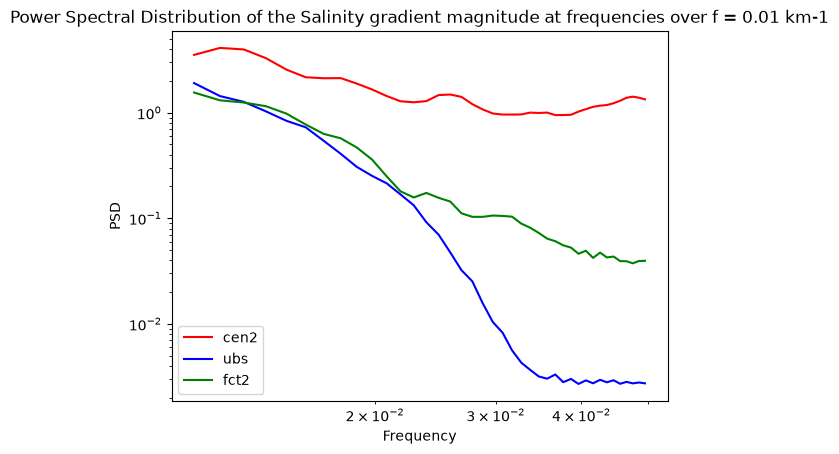

In [163]:
Fs = 1/10
cen2_fft=[[],[]]

for i in range(100):
    dataset = cen2.soce.isel(time_counter = -1, x_grid_T = i)
    cen2_soce = np.array(dataset)
    f_cen2, psd_cen2 = signal.welch(cen2_soce, Fs, nperseg = 101, window = 'tukey')
    cen2_fft[0].append(f_cen2)
    cen2_fft[1].append(psd_cen2)

psd_all = np.array(cen2_fft[1])      # shape (100, n_freq)

mask = f_cen2 > 0.01
f = f_cen2[mask]
moyennes = np.nanmean(psd_all, axis=tuple(range(psd_all.ndim - 1)))[mask] 

plt.loglog(f, moyennes, 'r', label = 'cen2')

ubs_fft = [[],[]]

for i in range(100):
    dataset = ubs.soce.isel(time_counter = -1, x_grid_T = i)
    f_ubs, psd_ubs = signal.welch(np.array(dataset), Fs, nperseg = 101, window = 'tukey')
    ubs_fft[0].append(f_ubs)
    ubs_fft[1].append(psd_ubs)
psd_all = np.array(ubs_fft[1])      # shape (100, n_freq)

mask = f_ubs > 0.01
f = f_ubs[mask]
moyennes = np.nanmean(psd_all, axis=tuple(range(psd_all.ndim - 1)))[mask] 

plt.loglog(f, moyennes, 'b', label = 'ubs')

fct2_fft = [[],[]]
for i in range(100):
    dataset = fct2.soce.isel(time_counter = -1, x_grid_T = i)
    f_fct2, psd_fct2 = signal.welch(np.array(dataset), Fs, nperseg = 101, window = 'tukey')
    fct2_fft[0].append(f_fct2)
    fct2_fft[1].append(psd_fct2)

psd_all = np.array(fct2_fft[1])      # shape (100, n_freq)

mask = f_fct2 > 0.01
f = f_fct2[mask]
moyennes = np.nanmean(psd_all, axis=tuple(range(psd_all.ndim - 1)))[mask] 

plt.loglog(f, moyennes, 'g', label = 'fct2')
#plt.loglog(f[5:20] , [k**(-5/3)/500 for k in f[5:20]], label = 'k^-5/3')
#plt.loglog(f[15:], [k**(-3)/300000 for k in f[15:]], label = 'k^-3')
plt.xlabel('Frequency')
plt.ylabel('PSD')
plt.title('Power Spectral Distribution of the Salinity gradient magnitude at frequencies over f = 0.01 km-1')
plt.legend()

To further our analysis on the smoothing of the salinity field, a power spectral distribution of the salinity gradient helps us identify at which frequency and therefore at which scale variance in the gradient field is most contributed.

At low frequencies (large-scale features), UBS and FCT2 should not differ much since the diffusion primarily attacks small scales first. 

At middle to high frequencies (50km to 25km), are where  small-scale structure lives (sharp fronts, fine filaments).The curve should drop because it is where the diffusive schemes damp the domain the fastest. 

At high frequencies (from 25km to 20km), keeping in mind that the grid definition is of 10km, that means changes from one point to its neighbour.  

The UBS curve shoulf be sitting below the FCT curve showing evidence that the UBS sheme is the most diffusive.

In [ ]:
cen2.close()
ubs.close()
fct2.close()